# Model Evaluation

In [1]:
from itertools import combinations
from joblib import load
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from MLstatkit import Delong_test
from mplsoccer import Pitch
from scipy.ndimage import gaussian_filter
from sklearn.cluster import KMeans
from sklearn.inspection import PartialDependenceDisplay, partial_dependence
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import normalize
from socceraction.atomic.vaep.formula import value
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from textwrap import fill
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm
from utils.modelling import grouped_permutation_importance
from utils.spatial_embeddings import (
    FreezeFramePointAutoencoder, 
    collate_freeze_frame_autoencoder,
    batched_chamfer_loss,    
)
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pickle
import pingouin as pg
import re
import seaborn as sns
import socceraction.atomic.spadl as atomicspadl
import torch
import umap

In [2]:
seed = 123
device = "cuda"

In [3]:
concedes_classifier_model = load("../models/classifiers/xgboost_all_concedes.pkl")
scores_classifier_model = load("../models/classifiers/xgboost_all_scores.pkl")

In [4]:
X_train = load("../data/modelling/train/X_train_dict.pkl")
y_train = load("../data/modelling/train/targets_train_dict.pkl")
X_test = load("../data/modelling/test/X_test_dict.pkl")
y_test = load("../data/modelling/test/targets_test_dict.pkl")

In [5]:
actions_data = []

for actions_file in os.listdir("../data/actions"):
    actions_data.append(
        pd.read_parquet(
            f"../data/actions/{actions_file}"
        )
    )

actions_df = atomicspadl.add_names(pd.concat(actions_data))

freeze_frames_df = actions_df[["game_id", "action_id", "event_uuid", "freeze_frame"]]

In [6]:
atomic_actions_df = pd.concat([X_train["all"], X_test["all"]])

atomic_actions_df = pd.merge(
    atomic_actions_df,
    pd.concat([y_train["concedes"], y_test["concedes"]]),
    on=["game_id", "action_id"],
    how="left"
)

atomic_actions_df = pd.merge(
    atomic_actions_df,
    pd.concat([y_train["scores"], y_test["scores"]]),
    on=["game_id", "action_id"],
    how="left"
)


In [7]:
atomic_actions_df["pconcedes"] = concedes_classifier_model.predict_proba(atomic_actions_df.drop(["game_id", "action_id", "concedes", "scores"], axis=1))[:,1]
atomic_actions_df["pscores"] = scores_classifier_model.predict_proba(atomic_actions_df.drop(["game_id", "action_id", "concedes", "scores", "pconcedes"], axis=1))[:,1]

In [8]:
atomic_actions_df = pd.merge(
    atomic_actions_df,
    actions_df[["game_id", "action_id", "team_id", "type_name"]],
    on=["game_id", "action_id"],
    how="left"
)

In [9]:
atomic_actions_df[["offensive_value", "defensive_value", "vaep_value"]] = value(
    atomic_actions_df,
    atomic_actions_df["pscores"], 
    atomic_actions_df["pconcedes"]
)

In [10]:
id_cols = ["game_id", "action_id"]

manual_spatial_feature_prefixes = [
    "actor_minimum_distance_to_opponent",
    "actor_minimum_distance_to_teammate",
    "actor_mean_distance_to_opponent",
    "actor_mean_distance_to_teammate",
    "actor_stdev_distance_to_opponent",
    "actor_stdev_distance_to_teammate",
    "number_of_opponents_within_radius_of_actor",
    "number_of_teammates_within_radius_of_actor",
    "opponent_convex_hull_area",
    "teammate_convex_hull_area",
]

manual_spatial_feature_cols = [
    c for c in X_train["all"].columns
    if any(c.startswith(prefix) for prefix in manual_spatial_feature_prefixes)
]

spatial_embedding_feature_cols = [
    c for c in X_train["all"].columns
    if c.startswith("spatial_embedding_")
]

baseline_feature_cols = [
    c for c in X_train["all"].columns
    if (
        c not in id_cols 
        and c not in manual_spatial_feature_cols
        and c not in spatial_embedding_feature_cols
    )
]

In [11]:
embedding_cols_df = pd.concat([X_train["all"], X_test["all"]])[id_cols + [i for i in spatial_embedding_feature_cols if i.endswith("a0")]]
print(embedding_cols_df.shape)
embedding_cols_df = embedding_cols_df.loc[~embedding_cols_df.drop(columns=["game_id", "action_id"]).eq(0).all(axis=1)]
print(embedding_cols_df.shape)

X_norm = normalize(embedding_cols_df.drop(id_cols, axis=1))

(929237, 66)
(776576, 66)


## Set Transformer Hyperparameters

In [ ]:
with open("../data/set_transformer/train_dataset.pkl", "rb") as f:
    train_dataset = pickle.load(f)

with open("../data/set_transformer/val_dataset.pkl", "rb") as f:
    val_dataset = pickle.load(f)

with open("../data/set_transformer/test_dataset.pkl", "rb") as f:
    test_dataset = pickle.load(f)

rng = np.random.default_rng(seed)

checkpoint = torch.load("../models/freeze_frame_point_autoencoder.pt", map_location=device)

params = checkpoint["best_params"]

model = FreezeFramePointAutoencoder( 
    embedding_dim=params["embedding_dim"], 
    max_players=22, 
    hidden_dim=params["hidden_dim"], 
    num_heads=params["num_heads"], 
    num_layers=params["num_layers"], 
    dropout=params["dropout"], 
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

train_idx = rng.choice(
    len(train_dataset),
    size=int(0.2 * len(train_dataset)),
    replace=False,
)

val_idx = rng.choice(
    len(val_dataset),
    size=int(0.2 * len(val_dataset)),
    replace=False,
)

test_idx = rng.choice(
    len(test_dataset),
    size=int(0.2 * len(test_dataset)),
    replace=False,
)

train_subset = Subset(train_dataset, train_idx)
val_subset = Subset(val_dataset, val_idx)
test_subset = Subset(test_dataset, val_idx)

train_loader = DataLoader(
    train_subset,
    batch_size=params["batch_size"],
    shuffle=True,
    collate_fn=collate_freeze_frame_autoencoder,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_subset,
    batch_size=params["batch_size"],
    shuffle=False,
    collate_fn=collate_freeze_frame_autoencoder,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_subset,
    batch_size=params["batch_size"],
    shuffle=False,
    collate_fn=collate_freeze_frame_autoencoder,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

layer_results = {}

for num_layers in [1, 2, 3, 4]:

    print(f"\nTraining {num_layers} encoder layer(s)")

    model = FreezeFramePointAutoencoder(
        embedding_dim=params["embedding_dim"],
        max_players=22,
        hidden_dim=params["hidden_dim"],
        num_heads=params["num_heads"],
        num_layers=num_layers,
        dropout=params["dropout"],
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"],
    )

    train_losses = []
    val_losses = []

    best_val = float("inf")
    best_epoch = -1

    for epoch in range(20):

        model.train()
        train_loss = 0.0

        for x, mask in train_loader:

            x = x.to(device)
            mask = mask.to(device)

            optimizer.zero_grad(set_to_none=True)

            recon, _ = model(x, mask)

            loss = batched_chamfer_loss(
                recon,
                x,
                mask,
                xy_weight=params["xy_weight"],
                flag_weight=params["flag_weight"],
            )

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * x.size(0)

        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0

        with torch.no_grad():

            for x, mask in val_loader:

                x = x.to(device)
                mask = mask.to(device)

                recon, _ = model(x, mask)

                loss = batched_chamfer_loss(
                    recon,
                    x,
                    mask,
                    xy_weight=params["xy_weight"],
                    flag_weight=params["flag_weight"],
                )

                val_loss += loss.item() * x.size(0)

        val_loss /= len(val_loader.dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_epoch = epoch + 1

        layer_results[num_layers] = {
            "train_losses": train_losses,
            "val_losses": val_losses,
            "best_val": best_val,
            "best_epoch": best_epoch,
        }

In [ ]:
plt.figure(figsize=(8,5))

for layers, results in layer_results.items():
    plt.plot(
        results["val_losses"],
        label=f"{layers} layer{'s' if layers > 1 else ''}"
    )

plt.xlabel("Epoch", fontweight="bold")
plt.ylabel("Validation loss", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/hyperparameter_num_of_layers_loss_comparison.png", dpi=300)
plt.show()

## Logistic Regression Classifier Coefficients

In [ ]:
concedes_lr_classifier_model = load("../models/classifiers/logistic_regression_all_concedes.pkl")
scores_lr_classifier_model = load("../models/classifiers/logistic_regression_all_scores.pkl")

In [ ]:
concedes_lr_coefficients_df = pd.DataFrame({
    "predictor": X_train["all"].drop(["game_id", "action_id"], axis=1).columns,
    "coefficients": concedes_lr_classifier_model.coef_[0],
    "odds ratio": np.exp(concedes_lr_classifier_model.coef_[0])
})

concedes_lr_coefficients_df

In [ ]:
scores_lr_coefficients_df = pd.DataFrame({
    "predictor": X_train["all"].drop(["game_id", "action_id"], axis=1).columns,
    "coefficients": scores_lr_classifier_model.coef_[0],
    "odds ratio": np.exp(scores_lr_classifier_model.coef_[0])
})

scores_lr_coefficients_df

## Model Performance Significance Tests

In [ ]:
concedes_results = []

for file in os.listdir("../models/classifiers"):

    if file.endswith(".pkl") and "concedes" in file:

        model_path = os.path.join("../models/classifiers", file)
        model = load(model_path)

        if "all" in model_path:
            df_type = "all"

        if "baseline" in model_path:
            df_type = "baseline"

        if "embeddings" in model_path:
            df_type = "embeddings"

        if "manual" in model_path:
            df_type = "manual"
        
        y_score = model.predict_proba(X_test[df_type].drop(["game_id", "action_id"], axis=1))[:, 1]

        auc = roc_auc_score(y_test["concedes"].drop(["game_id", "action_id"], axis=1), y_score)

        concedes_results.append({
            "model": file,
            "feature_set": df_type,
            "target": "concedes",
            "auc": auc,
            "predictions": y_score
        })

concedes_auc_df = pd.DataFrame(concedes_results)

In [ ]:
scores_results = []

for file in os.listdir("../models/classifiers"):

    if file.endswith(".pkl") and "scores" in file:

        model_path = os.path.join("../models/classifiers", file)
        model = load(model_path)

        if "all" in model_path:
            df_type = "all"

        if "baseline" in model_path:
            df_type = "baseline"

        if "embeddings" in model_path:
            df_type = "embeddings"

        if "manual" in model_path:
            df_type = "manual"
        
        y_score = model.predict_proba(X_test[df_type].drop(["game_id", "action_id"], axis=1))[:, 1]

        auc = roc_auc_score(y_test["scores"].drop(["game_id", "action_id"], axis=1), y_score)

        scores_results.append({
            "model": file,
            "feature_set": df_type,
            "target": "scores",
            "auc": auc,
            "predictions": y_score
        })

scores_auc_df = pd.DataFrame(scores_results)

In [ ]:
for model in ["logistic_regression", "random_forest", "xgboost", "catboost"]:

    comparison_df = concedes_auc_df[concedes_auc_df["model"].str.contains(model)]

    results = []

    for i, j in combinations(comparison_df.index, 2):

        row1 = comparison_df.loc[i]
        row2 = comparison_df.loc[j]

        result = Delong_test(
            y_test["concedes"].drop(["game_id", "action_id"], axis=1),
            row1["predictions"],
            row2["predictions"],
            verbose=1
        )

        z = result[0]
        p = result[1]

        results.append({
            "model": model,
            "comparison": f"{row1['feature_set']} vs {row2['feature_set']}",
            "z": z,
            "p": p,
            "auc_1": result[4],
            "auc_2": result[5],
            "delta_auc": result[5] - result[4]
        })

    results_df = pd.DataFrame(results)

    results_df["p_holm"] = multipletests(
        results_df["p"],
        method="holm"
    )[1]

    results_df[["comparison", "z", "p_holm", "delta_auc", "auc_1", "auc_2"]].to_parquet(
        f"../results/concedes_{model}_comparison_significance_test_results.parquet",
        compression="zstd",
        index=False
    )

In [ ]:
for model in ["logistic_regression", "random_forest", "xgboost", "catboost"]:

    comparison_df = scores_auc_df[scores_auc_df["model"].str.contains(model)]

    results = []

    for i, j in combinations(comparison_df.index, 2):

        row1 = comparison_df.loc[i]
        row2 = comparison_df.loc[j]

        result = Delong_test(
            y_test["scores"].drop(["game_id", "action_id"], axis=1),
            row1["predictions"],
            row2["predictions"],
            verbose=1
        )

        z = result[0]
        p = result[1]

        results.append({
            "model": model,
            "comparison": f"{row1['feature_set']} vs {row2['feature_set']}",
            "z": z,
            "p": p,
            "auc_1": result[4],
            "auc_2": result[5],
            "delta_auc": result[5] - result[4]
        })

    results_df = pd.DataFrame(results)

    results_df["p_holm"] = multipletests(
        results_df["p"],
        method="holm"
    )[1]

    results_df[["comparison", "z", "p_holm", "delta_auc", "auc_1", "auc_2"]].to_parquet(
        f"../results/scores_{model}_comparison_significance_test_results.parquet",
        compression="zstd",
        index=False
    )

## Permutation Importance

### Baseline vs Manual Spatial vs Embeddings

In [ ]:
feature_groups = {
    "baseline": baseline_feature_cols, 
    "manual_spatial": manual_spatial_feature_cols, 
    "embeddings": spatial_embedding_feature_cols
}

group_mode = {
    "baseline": "block", 
    "manual_spatial": "block", 
    "embeddings": "block"
}

concedes_classifier_permutation_importance_results = grouped_permutation_importance( 
    estimator=concedes_classifier_model, 
    X=X_train["all"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["concedes"].drop(["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=10, 
    random_state=seed
)

scores_classifier_permutation_importance_results = grouped_permutation_importance( 
    estimator=scores_classifier_model, 
    X=X_train["all"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["scores"].drop(["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=10, 
    random_state=seed
)

In [ ]:
concedes_classifier_rows = []
scores_classifier_rows = []

for feature, stats in concedes_classifier_permutation_importance_results.items():
    concedes_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

for feature, stats in scores_classifier_permutation_importance_results.items():
    scores_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

concedes_classifier_permutation_importance_df = pd.DataFrame(concedes_classifier_rows)
scores_classifier_permutation_importance_df = pd.DataFrame(scores_classifier_rows)

concedes_classifier_permutation_importance_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

scores_classifier_permutation_importance_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

concedes_classifier_permutation_importance_df.to_parquet(
    "../results/concedes_classifier_permutation_importance.parquet",
    compression="zstd",
    index=False,
)

scores_classifier_permutation_importance_df.to_parquet(
    "../results/scores_classifier_permutation_importance.parquet",
    compression="zstd",
    index=False,
)

In [ ]:
df1 = concedes_classifier_permutation_importance_df.set_index("feature")
df2 = scores_classifier_permutation_importance_df.set_index("feature")

df1, df2 = df1.align(df2, join="inner")

features = df1.index[::-1]
y = np.arange(len(features))

height = 0.4

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    y - height/2,
    df1["importance_mean"][::-1],
    height=height,
    xerr=df1["importance_std"][::-1],
    label="Concedes Classifier Model"
)

ax.barh(
    y + height/2,
    df2["importance_mean"][::-1],
    height=height,
    xerr=df2["importance_std"][::-1],
    label="Scores Classifier Model"
)

ax.set_yticks(y)
ax.set_yticklabels(features)

ax.set_xlabel("Mean decrease in AUC", fontweight="bold")
ax.set_xlim(0, 0.5)
ax.legend()

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/grouped_permutation_importance.png", dpi=300)
plt.show()

### Baseline Features Only

In [11]:
concedes_baseline_classifier_model = load("../models/classifiers/xgboost_baseline_concedes.pkl")
scores_baseline_classifier_model = load("../models/classifiers/xgboost_baseline_scores.pkl")

In [ ]:
baseline_features_unique_cols = set([re.sub(r"(_a\d+|_\d+)$", "", n) for n in baseline_feature_cols])
feature_groups = {}
group_mode = {}

for prefix in baseline_features_unique_cols:
    feature_groups[prefix] = [col for col in baseline_feature_cols if col.startswith(prefix)]
    group_mode[prefix] = "block"

concedes_classifier_permutation_importance_baseline_results = grouped_permutation_importance( 
    estimator=concedes_baseline_classifier_model, 
    X=X_train["baseline"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["concedes"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)


scores_classifier_permutation_importance_baseline_results = grouped_permutation_importance( 
    estimator=scores_baseline_classifier_model, 
    X=X_train["baseline"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["scores"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)

In [ ]:
concedes_classifier_rows = []
scores_classifier_rows = []

for feature, stats in concedes_classifier_permutation_importance_baseline_results.items():
    concedes_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

for feature, stats in scores_classifier_permutation_importance_baseline_results.items():
    scores_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

concedes_classifier_importance_baseline_df = pd.DataFrame(concedes_classifier_rows)
scores_classifier_importance_baseline_df = pd.DataFrame(scores_classifier_rows)

concedes_classifier_importance_baseline_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

scores_classifier_importance_baseline_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

concedes_classifier_importance_baseline_df.to_parquet(
    "../results/concedes_classifier_permutation_importance_baseline.parquet",
    compression="zstd",
    index=False,
)

scores_classifier_importance_baseline_df.to_parquet(
    "../results/scores_classifier_permutation_importance_baseline.parquet",
    compression="zstd",
    index=False,
)

In [ ]:
concedes_classifier_importance_baseline_top20_df = concedes_classifier_importance_baseline_df.iloc[:20]

plt.figure(figsize=(8, 4))

plt.barh(
    concedes_classifier_importance_baseline_top20_df["feature"][::-1],
    concedes_classifier_importance_baseline_top20_df["importance_mean"][::-1],
    xerr=concedes_classifier_importance_baseline_top20_df["importance_std"][::-1]
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Mean decrease in AUC", fontweight="bold")
plt.xlim(-0.02, 0.25)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/concedes_classifier_permutation_importance_baseline.png", dpi=300)
plt.show()

In [ ]:
scores_classifier_importance_baseline_top20_df = scores_classifier_importance_baseline_df.iloc[:20]

plt.figure(figsize=(8, 4))

plt.barh(
    scores_classifier_importance_baseline_top20_df["feature"][::-1],
    scores_classifier_importance_baseline_top20_df["importance_mean"][::-1],
    xerr=scores_classifier_importance_baseline_top20_df["importance_std"][::-1], 
    color="#ff7f0e"
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Mean decrease in AUC", fontweight="bold")
plt.xlim(-0.02, 0.25)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/scores_classifier_permutation_importance_baseline.png", dpi=300)
plt.show()

### Manual Spatial Features Only

In [17]:
concedes_manual_classifier_model = load("../models/classifiers/xgboost_manual_concedes.pkl")
scores_manual_classifier_model = load("../models/classifiers/xgboost_manual_scores.pkl")

In [ ]:
manual_features_unique_cols = set([re.sub(r"(_a\d+|_\d+)$", "", n) for n in manual_spatial_feature_cols])
feature_groups = {}
group_mode = {}

for prefix in manual_features_unique_cols:
    feature_groups[prefix] = [col for col in manual_spatial_feature_cols if col.startswith(prefix)]
    group_mode[prefix] = "block"

concedes_classifier_permutation_importance_manual_spatial_results = grouped_permutation_importance( 
    estimator=concedes_manual_classifier_model, 
    X=X_train["manual"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["concedes"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)

scores_classifier_permutation_importance_manual_spatial_results = grouped_permutation_importance( 
    estimator=scores_manual_classifier_model, 
    X=X_train["manual"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["scores"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)

In [ ]:
concedes_classifier_rows = []
scores_classifier_rows = []

for feature, stats in concedes_classifier_permutation_importance_manual_spatial_results.items():
    concedes_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

for feature, stats in scores_classifier_permutation_importance_manual_spatial_results.items():
    scores_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

concedes_classifier_importance_manual_spatial_df = pd.DataFrame(concedes_classifier_rows)
scores_classifier_importance_manual_spatial_df = pd.DataFrame(scores_classifier_rows)

concedes_classifier_importance_manual_spatial_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

scores_classifier_importance_manual_spatial_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

concedes_classifier_importance_manual_spatial_df.to_parquet(
    "../results/concedes_classifier_permutation_importance_manual_spatial.parquet",
    compression="zstd",
    index=False,
)

scores_classifier_importance_manual_spatial_df.to_parquet(
    "../results/scores_classifier_permutation_importance_manual_spatial.parquet",
    compression="zstd",
    index=False,
)

In [ ]:
concedes_classifier_importance_manual_spatial_top20_df = concedes_classifier_importance_manual_spatial_df.iloc[:20]

plt.figure(figsize=(10, 6))

plt.barh(
    concedes_classifier_importance_manual_spatial_top20_df["feature"][::-1],
    concedes_classifier_importance_manual_spatial_top20_df["importance_mean"][::-1],
    xerr=concedes_classifier_importance_manual_spatial_top20_df["importance_std"][::-1]
)

plt.xlabel("Mean decrease in score", fontweight="bold")
plt.xlim(0, 0.005)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/concedes_classifier_permutation_importance_manual_spatial.png", dpi=300)
plt.show()

In [ ]:
scores_classifier_importance_manual_spatial_top20_df = scores_classifier_importance_manual_spatial_df.iloc[:20]

plt.figure(figsize=(10, 6))

plt.barh(
    scores_classifier_importance_manual_spatial_top20_df["feature"][::-1],
    scores_classifier_importance_manual_spatial_top20_df["importance_mean"][::-1],
    xerr=scores_classifier_importance_manual_spatial_top20_df["importance_std"][::-1], 
    color="#ff7f0e"
)

plt.xlabel("Mean decrease in score", fontweight="bold")
plt.xlim(0, 0.005)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/scores_classifier_permutation_importance_manual_spatial.png", dpi=300)
plt.show()

### Embeddings Only

In [ ]:
concedes_embeddings_classifier_model = load("../models/classifiers/xgboost_embeddings_concedes.pkl")
scores_embeddings_classifier_model = load("../models/classifiers/xgboost_embeddings_scores.pkl")

spatial_embeddings_unique_cols = set([re.sub(r"(_a\d+|_\d+)$", "", n) for n in spatial_embedding_feature_cols])
feature_groups = {}
group_mode = {}

for prefix in spatial_embeddings_unique_cols:
    feature_groups[prefix] = [col for col in spatial_embedding_feature_cols if col.startswith(prefix)]
    group_mode[prefix] = "block"

concedes_classifier_permutation_importance_embeddings_results = grouped_permutation_importance( 
    estimator=concedes_embeddings_classifier_model, 
    X=X_train["embeddings"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["concedes"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)

scores_classifier_permutation_importance_embeddings_results = grouped_permutation_importance( 
    estimator=scores_embeddings_classifier_model, 
    X=X_train["embeddings"].drop(columns=["game_id", "action_id"], axis=1), 
    y=y_train["scores"].drop(columns=["game_id", "action_id"], axis=1), 
    feature_groups=feature_groups, 
    group_mode=group_mode, 
    scoring="roc_auc", 
    n_repeats=5, 
    random_state=seed
)

In [ ]:
concedes_classifier_rows = []
scores_classifier_rows = []

for feature, stats in concedes_classifier_permutation_importance_embeddings_results.items():
    concedes_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

for feature, stats in scores_classifier_permutation_importance_embeddings_results.items():
    scores_classifier_rows.append({
        "feature": feature,
        "importance_mean": stats["mean"],
        "importance_std": stats["std"],
    })

concedes_classifier_importance_embeddings_df = pd.DataFrame(concedes_classifier_rows)
scores_classifier_importance_embeddings_df = pd.DataFrame(scores_classifier_rows)

concedes_classifier_importance_embeddings_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)

scores_classifier_importance_embeddings_df.sort_values(
    "importance_mean",
    ascending=False,
    inplace=True,
)


concedes_classifier_importance_embeddings_df.to_parquet(
    "../results/concedes_classifier_permutation_importance_embeddings.parquet",
    compression="zstd",
    index=False,
)

scores_classifier_importance_embeddings_df.to_parquet(
    "../results/scores_classifier_permutation_importance_embeddings.parquet",
    compression="zstd",
    index=False,
)

In [ ]:
plt.figure(figsize=(8, 10))

plt.barh(
    concedes_classifier_importance_embeddings_df["feature"][::-1],
    concedes_classifier_importance_embeddings_df["importance_mean"][::-1],
    xerr=concedes_classifier_importance_embeddings_df["importance_std"][::-1]
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Mean decrease in score", fontweight="bold")
plt.xlim(-0.00025, 0.0035)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/concedes_classifier_permutation_importance_embeddings.png", dpi=300)
plt.show()

In [ ]:
plt.figure(figsize=(8, 10))

plt.barh(
    scores_classifier_importance_embeddings_df["feature"][::-1],
    scores_classifier_importance_embeddings_df["importance_mean"][::-1],
    xerr=scores_classifier_importance_embeddings_df["importance_std"][::-1], 
    color="#ff7f0e"
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Mean decrease in score", fontweight="bold")
plt.xlim(-0.00025, 0.0035)
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/scores_classifier_permutation_importance_embeddings.png", dpi=300)
plt.show()

### Correlations Between Manual Spatial Features and Embeddings

In [ ]:
manual_embeddings_cols_df = X_train["all"].drop(columns=["game_id", "action_id"], axis=1)[
    [c for c in manual_spatial_feature_cols if c.endswith("a0")] +
    [c for c in spatial_embedding_feature_cols if c.endswith("a0")]
]

In [ ]:
corr = manual_embeddings_cols_df.corr()

corr_block = corr.loc[
    [c for c in manual_spatial_feature_cols if c.endswith("a0")],
    [c for c in spatial_embedding_feature_cols if c.endswith("a0")],
]

corr_block.index = [c.replace("_a0", "").replace("_", " ") for c in corr_block.index]
corr_block.columns = [c.replace("_a0", "") for c in corr_block.columns]

y_tick_labels = [
    fill(label.replace("_", " "), width=20)
    for label in corr_block.index
]

x_tick_labels = [
    c.split("_")[2]
    for c in corr_block.columns
]

plt.figure(figsize=(12, 6))

ax = sns.heatmap(
    corr_block,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    linecolor="white",
    xticklabels=x_tick_labels,
    yticklabels=y_tick_labels,
)

plt.xlabel("Embedding Dimensions", fontweight="bold")

plt.ylabel("Manually-Engineered\n Spatial Features", fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/manual_embeddings_corr_heatmap.png", dpi=300)
plt.show()

## Partial Dependence Plots

In [ ]:
X_pdp = X_train["baseline"].drop(columns=["game_id", "action_id"], axis=1).sample(n=10_000, random_state=seed)
X_pdp["goalscore_diff"] = X_pdp["goalscore_diff"].astype(float)

KeyboardInterrupt: 

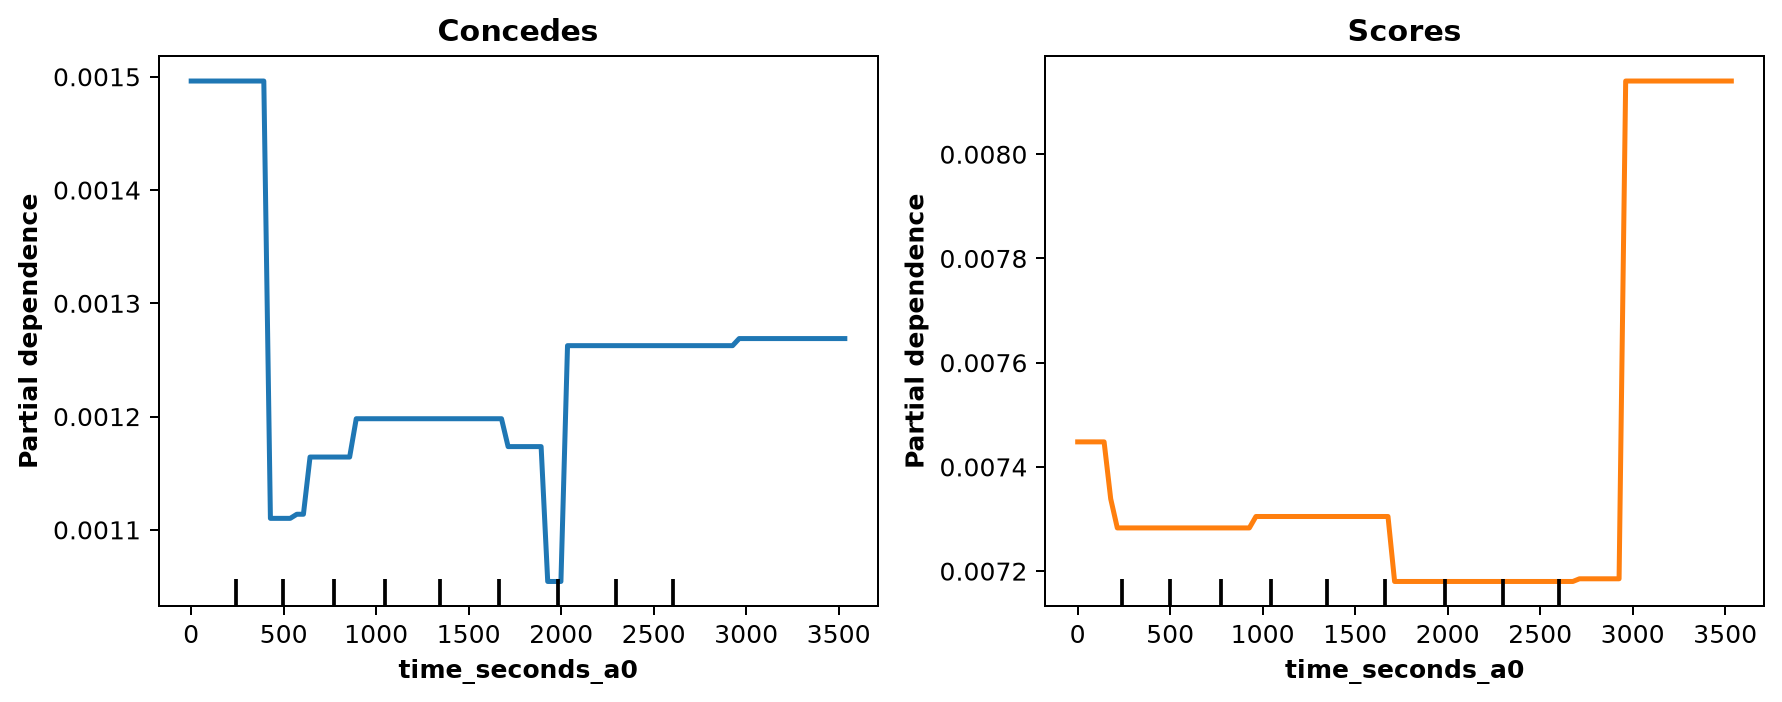

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

disp1 = PartialDependenceDisplay.from_estimator(
    estimator=concedes_baseline_classifier_model,
    X=X_pdp,
    features=["time_seconds_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[0],
    line_kw={"color": "tab:blue", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[0].set_title("Concedes", fontweight="bold")
disp1.axes_[0, 0].xaxis.label.set_weight("bold")
disp1.axes_[0, 0].yaxis.label.set_weight("bold")

disp2 = PartialDependenceDisplay.from_estimator(
    estimator=scores_baseline_classifier_model,
    X=X_pdp,
    features=["time_seconds_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[1],
    line_kw={"color": "tab:orange", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[1].set_title("Scores", fontweight="bold")
disp2.axes_[0, 0].xaxis.label.set_weight("bold")
disp2.axes_[0, 0].yaxis.label.set_weight("bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/pdp_most_important_concede_baseline_feature.png", dpi=300)
plt.show()

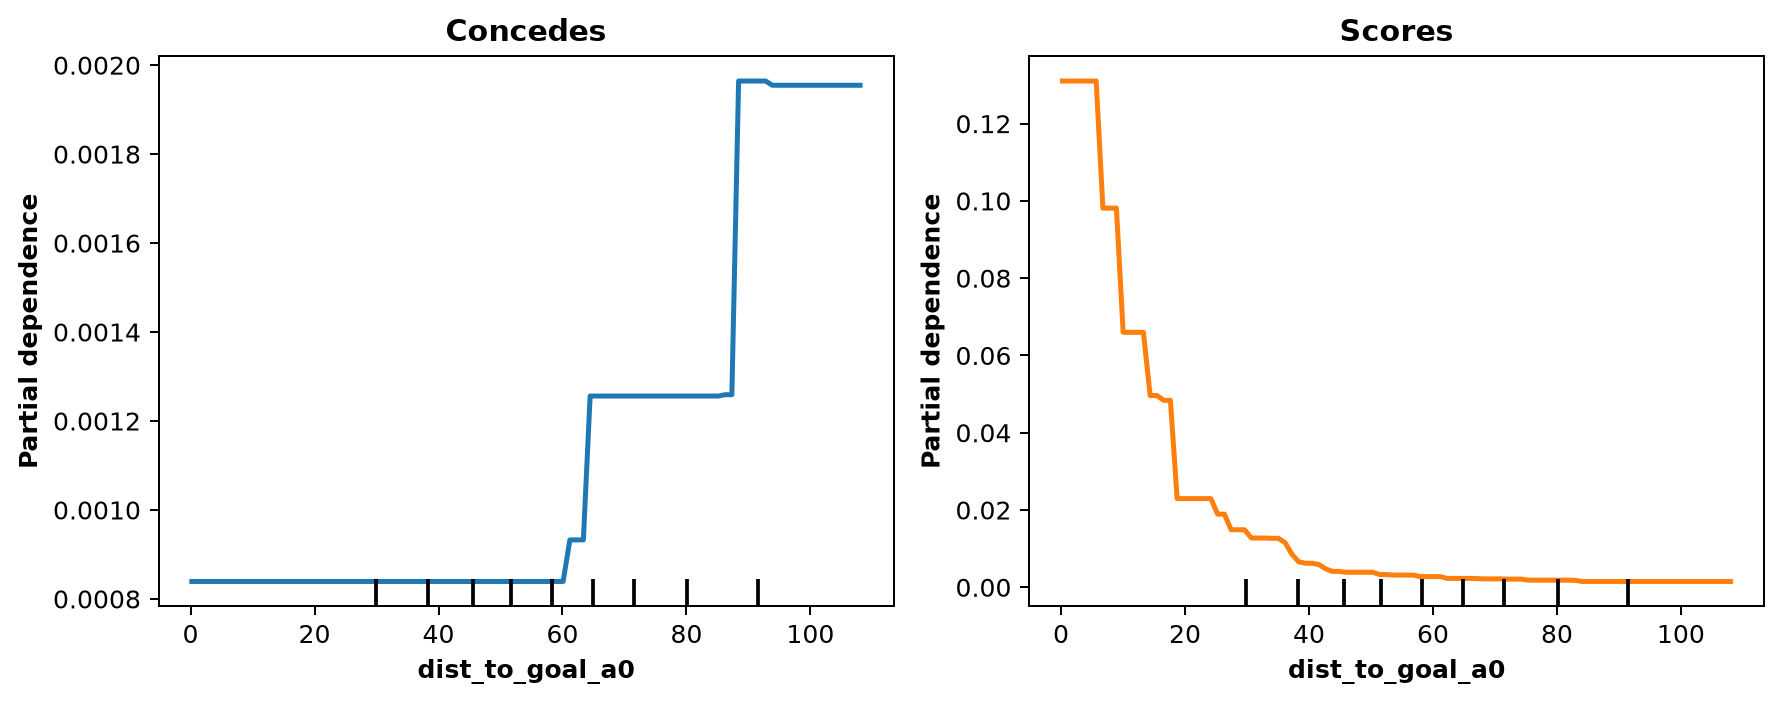

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

disp1 = PartialDependenceDisplay.from_estimator(
    estimator=concedes_baseline_classifier_model,
    X=X_pdp,
    features=["dist_to_goal_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[0],
    line_kw={"color": "tab:blue", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[0].set_title("Concedes", fontweight="bold")
disp1.axes_[0, 0].xaxis.label.set_weight("bold")
disp1.axes_[0, 0].yaxis.label.set_weight("bold")

disp2 = PartialDependenceDisplay.from_estimator(
    estimator=scores_baseline_classifier_model,
    X=X_pdp,
    features=["dist_to_goal_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[1],
    line_kw={"color": "tab:orange", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[1].set_title("Scores", fontweight="bold")
disp2.axes_[0, 0].xaxis.label.set_weight("bold")
disp2.axes_[0, 0].yaxis.label.set_weight("bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/pdp_most_important_score_baseline_feature.png", dpi=300)
plt.show()

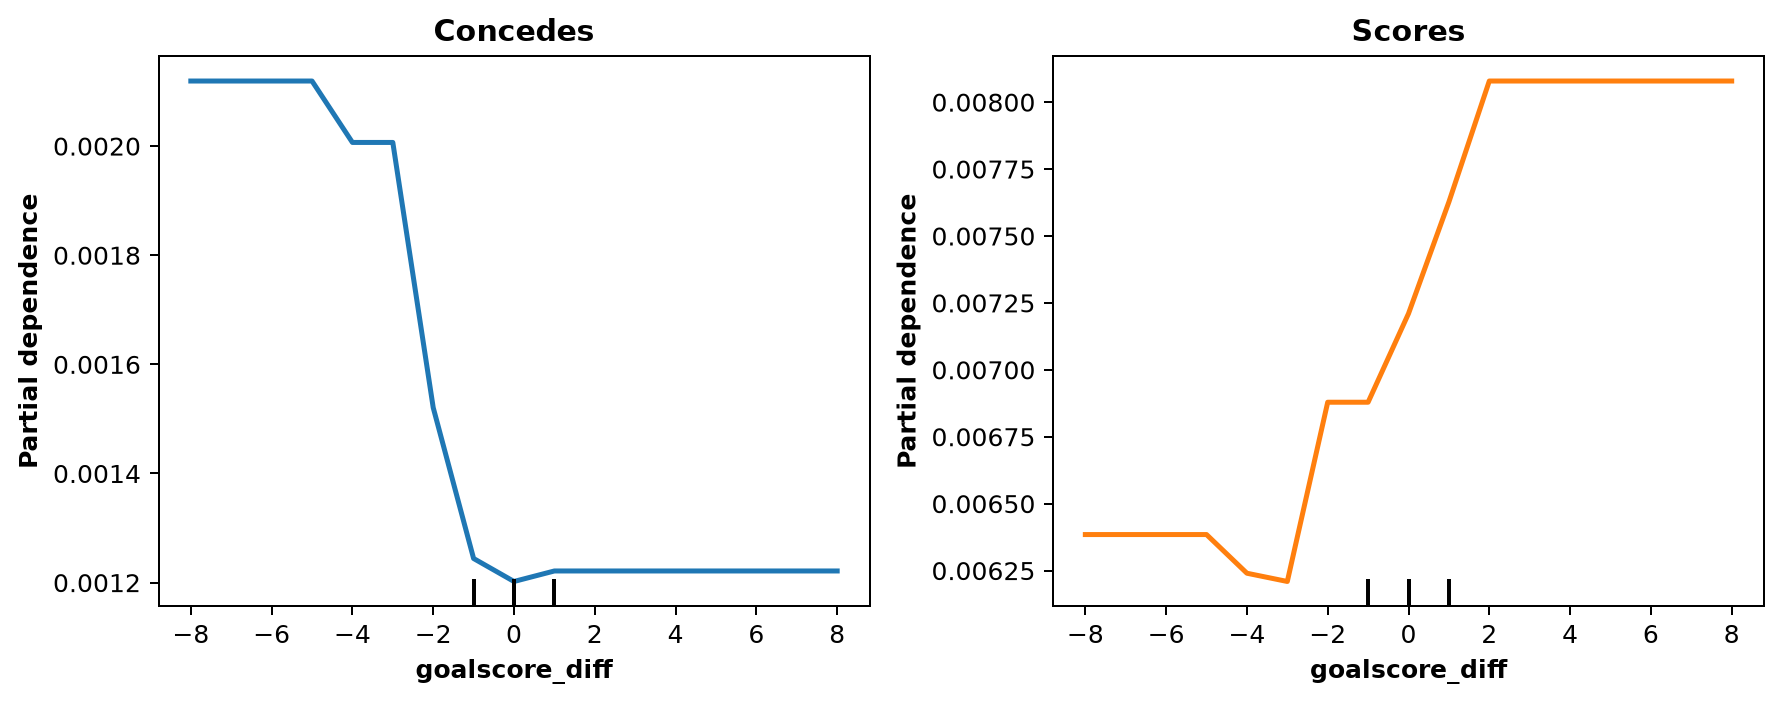

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

disp1 = PartialDependenceDisplay.from_estimator(
    estimator=concedes_baseline_classifier_model,
    X=X_pdp,
    features=["goalscore_diff"],
    response_method="predict_proba",
    kind="average",
    ax=axes[0],
    line_kw={"color": "tab:blue", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[0].set_title("Concedes", fontweight="bold")
disp1.axes_[0, 0].xaxis.label.set_weight("bold")
disp1.axes_[0, 0].yaxis.label.set_weight("bold")

disp2 = PartialDependenceDisplay.from_estimator(
    estimator=scores_baseline_classifier_model,
    X=X_pdp,
    features=["goalscore_diff"],
    response_method="predict_proba",
    kind="average",
    ax=axes[1],
    line_kw={"color": "tab:orange", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[1].set_title("Scores", fontweight="bold")
disp2.axes_[0, 0].xaxis.label.set_weight("bold")
disp2.axes_[0, 0].yaxis.label.set_weight("bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/pdp_goalscore_diff.png", dpi=300)
plt.show()

In [20]:
X_pdp_manual = X_train["manual"].drop(columns=["game_id", "action_id"], axis=1).sample(n=10_000, random_state=seed)
X_pdp_manual["goalscore_diff"] = X_pdp_manual["goalscore_diff"].astype(float)

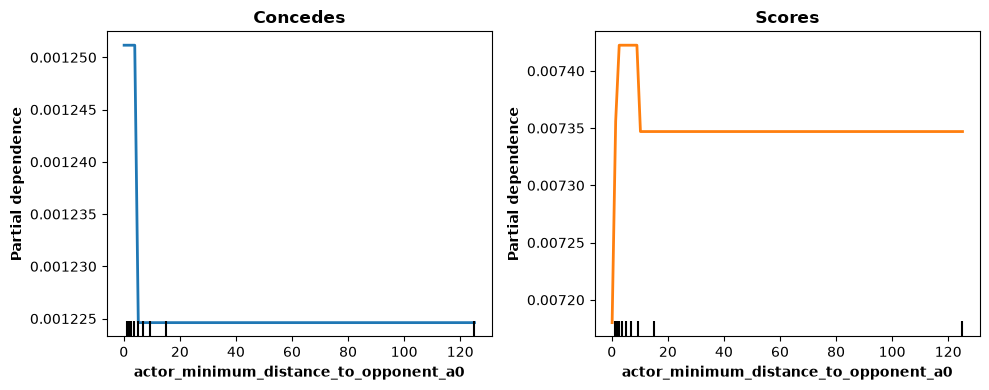

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

disp1 = PartialDependenceDisplay.from_estimator(
    estimator=concedes_manual_classifier_model,
    X=X_pdp_manual,
    features=["actor_minimum_distance_to_opponent_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[0],
    line_kw={"color": "tab:blue", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[0].set_title("Concedes", fontweight="bold")
disp1.axes_[0, 0].xaxis.label.set_weight("bold")
disp1.axes_[0, 0].yaxis.label.set_weight("bold")

disp2 = PartialDependenceDisplay.from_estimator(
    estimator=scores_manual_classifier_model,
    X=X_pdp_manual,
    features=["actor_minimum_distance_to_opponent_a0"],
    response_method="predict_proba",
    kind="average",
    ax=axes[1],
    line_kw={"color": "tab:orange", "linewidth": 2},
    percentiles=(0, 1),
    random_state=seed
)

axes[1].set_title("Scores", fontweight="bold")
disp2.axes_[0, 0].xaxis.label.set_weight("bold")
disp2.axes_[0, 0].yaxis.label.set_weight("bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/pdp_actor_minimum_distance_to_opponents.png", dpi=300)
plt.show()

In [ ]:
pitch = Pitch(
    pitch_type="custom",
    pitch_length=105,
    pitch_width=68,
)

fig, axes = plt.subplots(2, 1, figsize=(8, 10))

bs_score = pitch.bin_statistic(
    atomic_actions_df["x_a0"],
    atomic_actions_df["y_a0"],
    values=atomic_actions_df["pscores"],
    statistic="mean",
    bins=(30, 20),
)

bs_concede = pitch.bin_statistic(
    atomic_actions_df["x_a0"],
    atomic_actions_df["y_a0"],
    values=atomic_actions_df["pconcedes"],
    statistic="mean",
    bins=(30, 20),
)

pitch.draw(ax=axes[0])
pitch.draw(ax=axes[1])

pitch.heatmap(bs_score, ax=axes[0], cmap="Oranges", alpha=0.7)
axes[0].set_title("Scores", fontweight="bold")

pitch.heatmap(bs_concede, ax=axes[1], cmap="Blues", alpha=0.7)
axes[1].set_title("Concedes", fontweight="bold")

plt.tight_layout()
plt.show()

## Embeddings Clustering

In [35]:
k_means_hyperparameter_tuning_results = {
    "k": [],
    "calinski_harabasz_score": [],
    "davies_bouldin_score": [],
    "inertia": [],
    "silhouette_score": [],
}

for k in range(2, 11):

    km = KMeans(n_clusters=k, random_state=seed, n_init="auto")
    labels = km.fit_predict(X_norm)

    score_silhouette = silhouette_score(X_norm, labels, sample_size=10_000, random_state=seed)
    score_davies_boudlin = davies_bouldin_score(X_norm, labels)
    score_calinski_harabasz = calinski_harabasz_score(X_norm, labels)

    k_means_hyperparameter_tuning_results["k"].append(k)
    k_means_hyperparameter_tuning_results["calinski_harabasz_score"].append(score_calinski_harabasz)
    k_means_hyperparameter_tuning_results["davies_bouldin_score"].append(score_davies_boudlin)
    k_means_hyperparameter_tuning_results["inertia"].append(km.inertia_)
    k_means_hyperparameter_tuning_results["silhouette_score"].append(score_silhouette)

In [36]:
k_means_hyperparameter_tuning_results_df = pd.DataFrame(k_means_hyperparameter_tuning_results)

k_means_hyperparameter_tuning_results_df.to_parquet(
    "../results/k_means_hyperparameter_tuning_results.parquet", 
    compression="zstd", 
    index=False
)

k_means_hyperparameter_tuning_results_df

,k,calinski_harabasz_score,davies_bouldin_score,inertia,silhouette_score
0,2,584394.715892,1.106755,126130.187500,0.375978
1,3,455212.672617,1.367771,101754.562500,0.254624
2,4,362375.968674,1.523669,92106.718750,0.243309
3,5,312934.939794,1.548552,84631.625000,0.188064
4,6,278635.378067,1.598667,79114.398438,0.181494
5,7,248554.276094,1.646839,75690.851562,0.157332
6,8,229862.087702,1.665479,71955.789062,0.147642
7,9,210963.562560,1.719838,69658.804688,0.135270
8,10,195619.024972,1.792463,67658.273438,0.128882


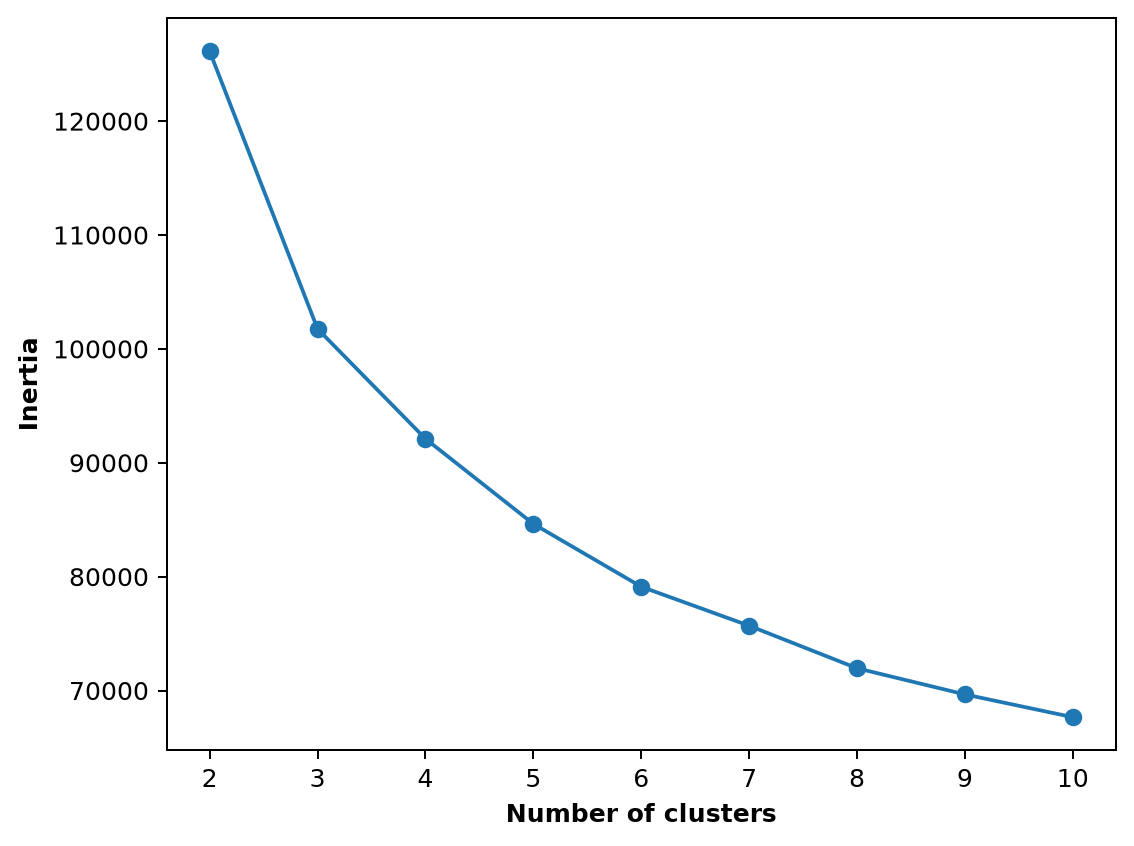

In [37]:
plt.plot(range(2,11), k_means_hyperparameter_tuning_results["inertia"], marker="o")
plt.xlabel("Number of clusters", fontweight="bold")
plt.ylabel("Inertia", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/kmeans_elbow_plot.png", dpi=300)
plt.show()

In [21]:
km = KMeans(
    n_clusters=2,
    random_state=seed,
    n_init="auto"
)

embedding_cols_df = embedding_cols_df.copy()
clusters = km.fit_predict(X_norm)
embedding_cols_df["kmeans_labels"] = clusters

In [39]:
embeddings_cols_with_vaep_df = pd.merge(
    embedding_cols_df,
    atomic_actions_df[["game_id", "action_id", "vaep_value"]],
    on=["game_id", "action_id"],
    how="left"
)

In [40]:
embeddings_with_freeze_frames_df = embeddings_cols_with_vaep_df.merge(
    freeze_frames_df,
    on=["game_id", "action_id"],
    how="left"
)

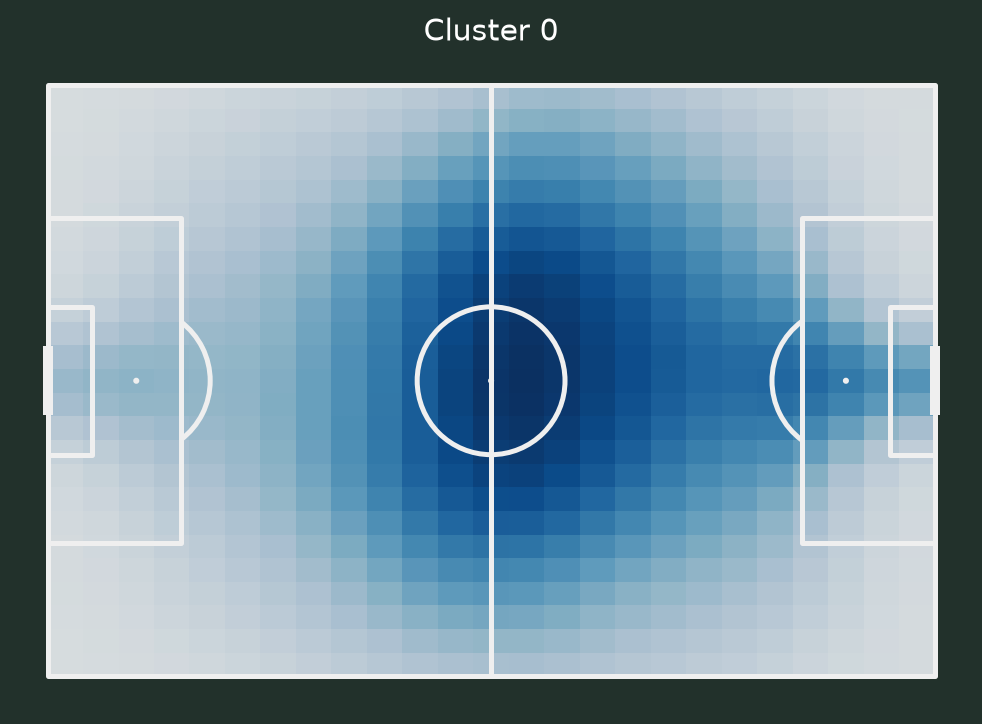

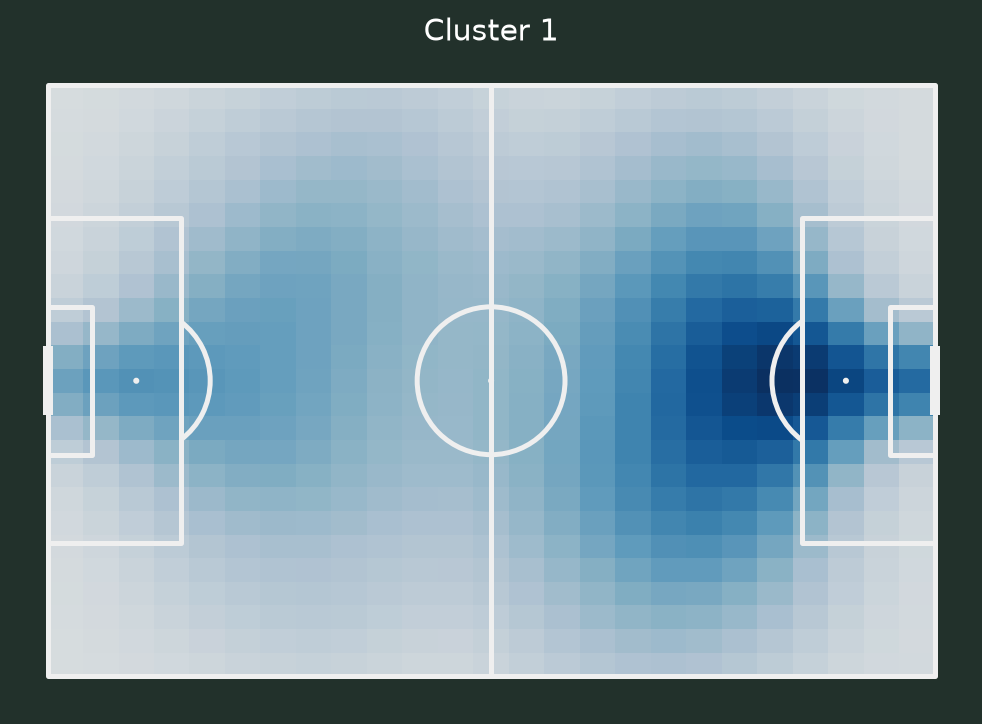

In [41]:
pitch = Pitch(
    pitch_type="statsbomb",
    line_zorder=2,
    pitch_color="#22312b",
    line_color="#efefef"
)

for cluster, cluster_df in embeddings_with_freeze_frames_df.groupby("kmeans_labels"):

    xs, ys = [], []

    for freeze_frame in cluster_df["freeze_frame"]:
        if not freeze_frame:
            continue

        for player in freeze_frame:

            loc = player.get("location")
            if loc is None:
                continue

            xs.append(loc[0])
            ys.append(loc[1])

    fig, ax = pitch.draw(figsize=(6.6, 4.125))
    fig.set_facecolor("#22312b")

    if len(xs) > 0:
        team_bin = pitch.bin_statistic(
            xs,
            ys,
            statistic="count",
            bins=(25, 25)
        )
        team_bin["statistic"] = gaussian_filter(team_bin["statistic"], 1)

        pitch.heatmap(
            team_bin,
            ax=ax,
            cmap="Blues",
            alpha=0.85,
            edgecolors=None
        )

    ax.set_title(f"Cluster {cluster}", color="white")
    plt.tight_layout()
    plt.savefig(f"../reports/dissertation/figures/kmeans_cluster_{cluster}_heatmap.png", dpi=300)
    plt.show()

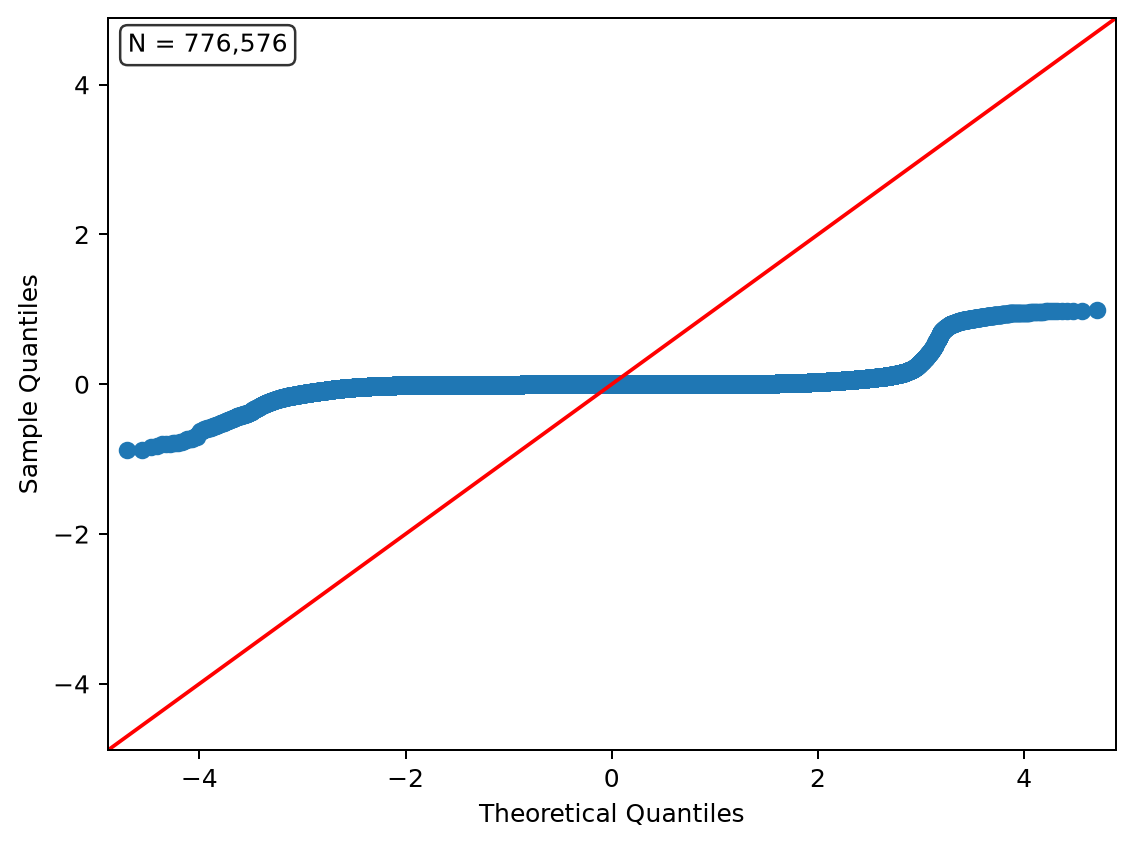

In [42]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

model = smf.ols(
    "vaep_value ~ C(kmeans_labels)", 
    data=embeddings_cols_with_vaep_df[["kmeans_labels", "vaep_value"]]
).fit()

fig = sm.qqplot(model.resid, line="45")
ax = fig.axes[0]

ax.text(
    0.02, 0.98,
    f"N = {int(model.nobs):,}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/kmeans_label_vaep_comparison_normality_qqplot.png", dpi=300)
plt.show()

In [ ]:
variance_comparison_df = embeddings_cols_with_vaep_df.groupby("kmeans_labels")["vaep_value"].agg(["count", "mean", "var"])
variance_comparison_df.to_parquet(
    "../results/kmeans_label_vaep_variance_comparison.parquet",
    compression="zstd",
    index=False
)
variance_comparison_df

,count,mean,var
kmeans_labels,,,
0,501617,0.002415,0.000804
1,274959,0.003074,0.001134


In [ ]:
group_0 = embeddings_cols_with_vaep_df.loc[embeddings_cols_with_vaep_df["kmeans_labels"] == 0, "vaep_value"].dropna()
group_1 = embeddings_cols_with_vaep_df.loc[embeddings_cols_with_vaep_df["kmeans_labels"] == 1, "vaep_value"].dropna()

pg.ttest(
    group_0,
    group_1,
    correction=True
)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-8.708376,489849.34673,two-sided,3.091892e-18,"[-0.0, -0.0]",0.021715,1.0,7.837e+13


In [52]:
embeddings_cols_with_vaep_df["vaep_value"].mean()

0.0026480441

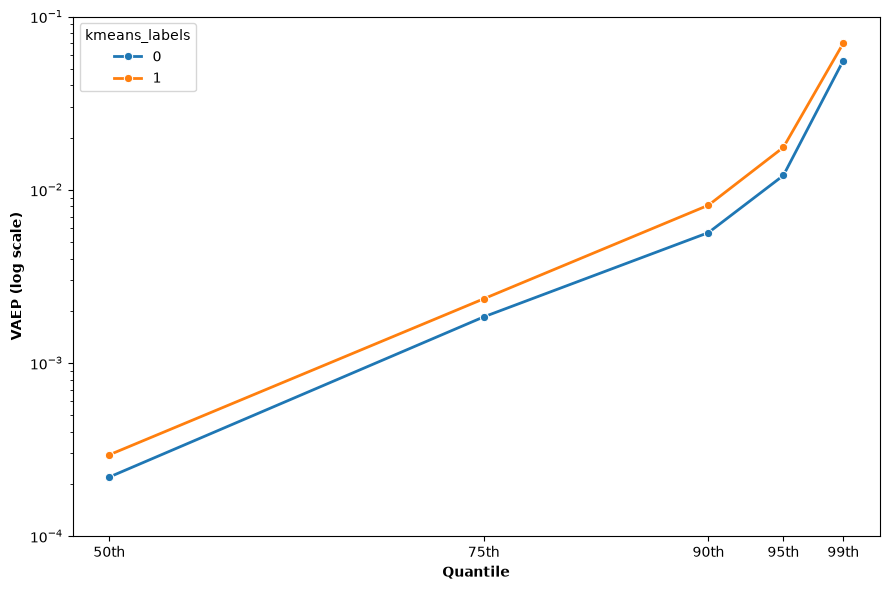

In [75]:
quantile_df = embeddings_cols_with_vaep_df.groupby('kmeans_labels')['vaep_value'].quantile(
    [0.5, 0.75, 0.90, 0.95, 0.99]
).reset_index()

plt.figure(figsize=(9, 6))

sns.lineplot(
    data=quantile_df,
    x='level_1',
    y='vaep_value',
    hue='kmeans_labels',
    marker='o',
    linewidth=2
)

plt.xticks(
    [0.50, 0.75, 0.90, 0.95, 0.99],
    ['50th', '75th', '90th', '95th', '99th']
)

plt.yscale("log")
plt.ylim(1e-4, 1e-1)

plt.xlabel('Quantile', fontweight="bold")
plt.ylabel('VAEP (log scale)', fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/kmeans_vaep_comparison_quantile.png", dpi=300)
plt.show()

In [46]:
kmeans_labels_with_manual_spatial_features_df = pd.merge(
    atomic_actions_df[["game_id", "action_id"] + [c + "_a0" for c in manual_spatial_feature_prefixes]],
    embeddings_cols_with_vaep_df[["game_id", "action_id", "kmeans_labels"]],
    on=["game_id", "action_id"],
    how="left"
)

In [47]:
(
    kmeans_labels_with_manual_spatial_features_df
    .drop(["game_id", "action_id"], axis=1)
    .groupby("kmeans_labels")
    .mean()
    .reset_index()
)

,kmeans_labels,actor_minimum_distance_to_opponent_a0,actor_minimum_distance_to_teammate_a0,actor_mean_distance_to_opponent_a0,actor_mean_distance_to_teammate_a0,actor_stdev_distance_to_opponent_a0,actor_stdev_distance_to_teammate_a0,number_of_opponents_within_radius_of_actor_a0,number_of_teammates_within_radius_of_actor_a0,opponent_convex_hull_area_a0,teammate_convex_hull_area_a0
0,0.0,5.416480,9.304686,17.643570,20.072252,8.297873,8.326468,0.840221,0.205814,394.915375,571.466736
1,1.0,5.431177,9.330997,17.479273,19.815451,8.177195,8.097359,0.897799,0.245055,368.403656,519.314575


## UMAP

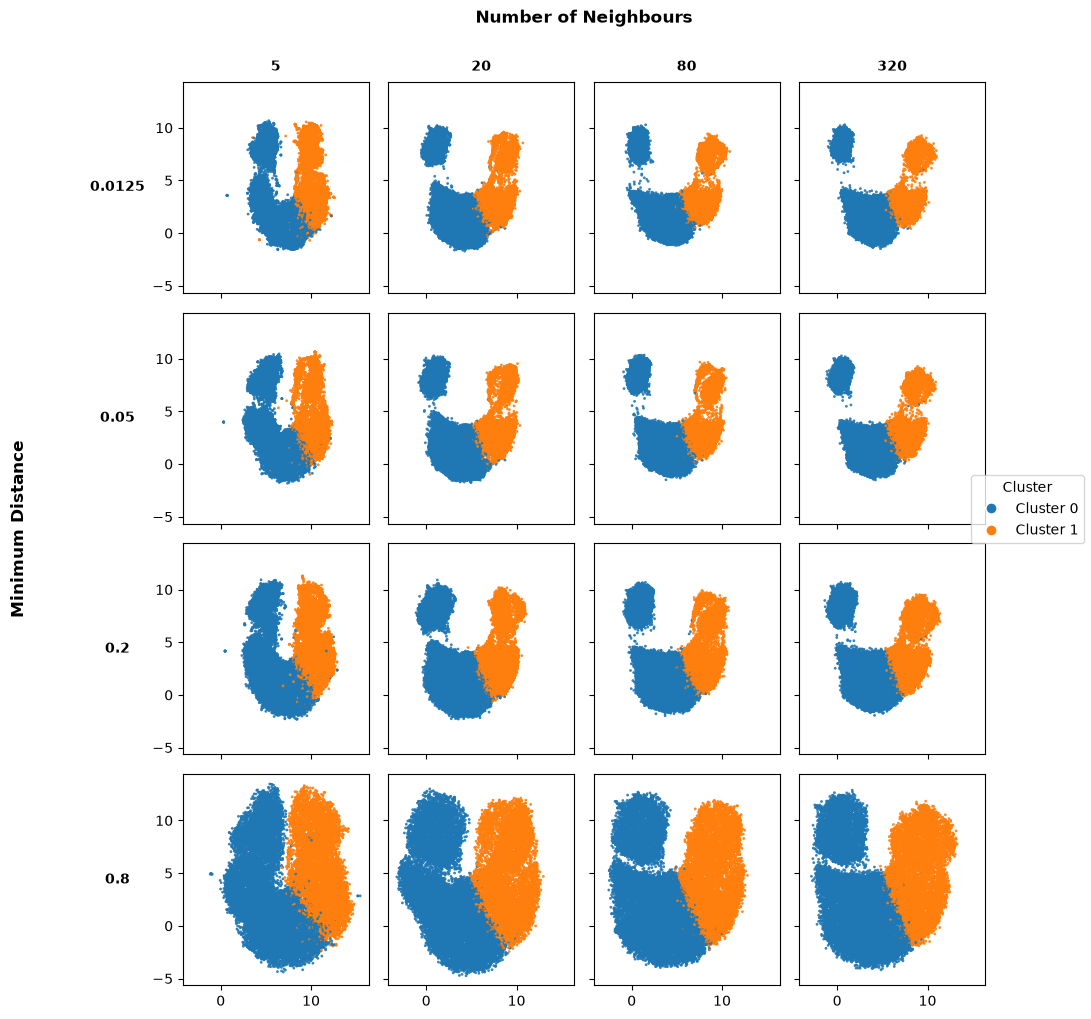

In [53]:
X_umap = embedding_cols_df.drop(["game_id", "action_id"], axis=1)

idx = np.random.choice(
    len(X_umap),
    size=20_000,
    replace=False
)

X_sub = X_umap.iloc[idx]

labels_sub = embedding_cols_df.iloc[idx]["kmeans_labels"].to_numpy()

cmap = ListedColormap(["tab:blue", "tab:orange"])

n_neighbors_list = [5, 20, 80, 320]
min_dist_list = [0.0125, 0.05, 0.2, 0.8]

fig, axes = plt.subplots(
    len(min_dist_list),
    len(n_neighbors_list),
    figsize=(11, 11),
    sharex=True,
    sharey=True
)

for i, min_dist in enumerate(min_dist_list):
    for j, n_neighbors in enumerate(n_neighbors_list):

        reducer = umap.UMAP(
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            n_components=2,
            metric="cosine",
            random_state=seed,
            n_epochs=20
        )

        embedding = reducer.fit_transform(X_sub)

        ax = axes[i, j]

        scatter = ax.scatter(
            embedding[:, 0],
            embedding[:, 1],
            c=labels_sub,
            cmap=cmap,
            s=4,
            alpha=0.9,
            linewidths=0
        )

        if i == 0:
            ax.set_title(
                f"{n_neighbors}",
                fontsize=10,
                fontweight="bold",
                pad=8
            )

        if j == 0:
            ax.set_ylabel(
                f"{min_dist}",
                fontsize=10,
                fontweight="bold",
                rotation=0,
                labelpad=25,
                va="center"
            )

fig.supylabel(
    "Minimum Distance",
    fontsize=12,
    fontweight="bold",
    x=0.02       
)

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           label="Cluster 0",
           markerfacecolor="tab:blue", markersize=8),
    Line2D([0], [0], marker="o", color="w",
           label="Cluster 1",
           markerfacecolor="tab:orange", markersize=8),
]

fig.legend(
    handles=legend_elements,
    loc="center right",
    title="Cluster"
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    left=0.08,
    right=0.92,
    top=0.93,
    bottom=0.05
)

plt.tight_layout(rect=[0.05, 0.05, 0.92, 0.94])

top = axes[0, 0].get_position().y1
left = axes[0, 0].get_position().x0
right = axes[0, -1].get_position().x1

fig.text(
    (left + right) / 2,
    top + 0.05,
    "Number of Neighbours",
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)

plt.savefig("../reports/dissertation/figures/umap_hyperparameter_range_clusters.png", dpi=300)
plt.show()

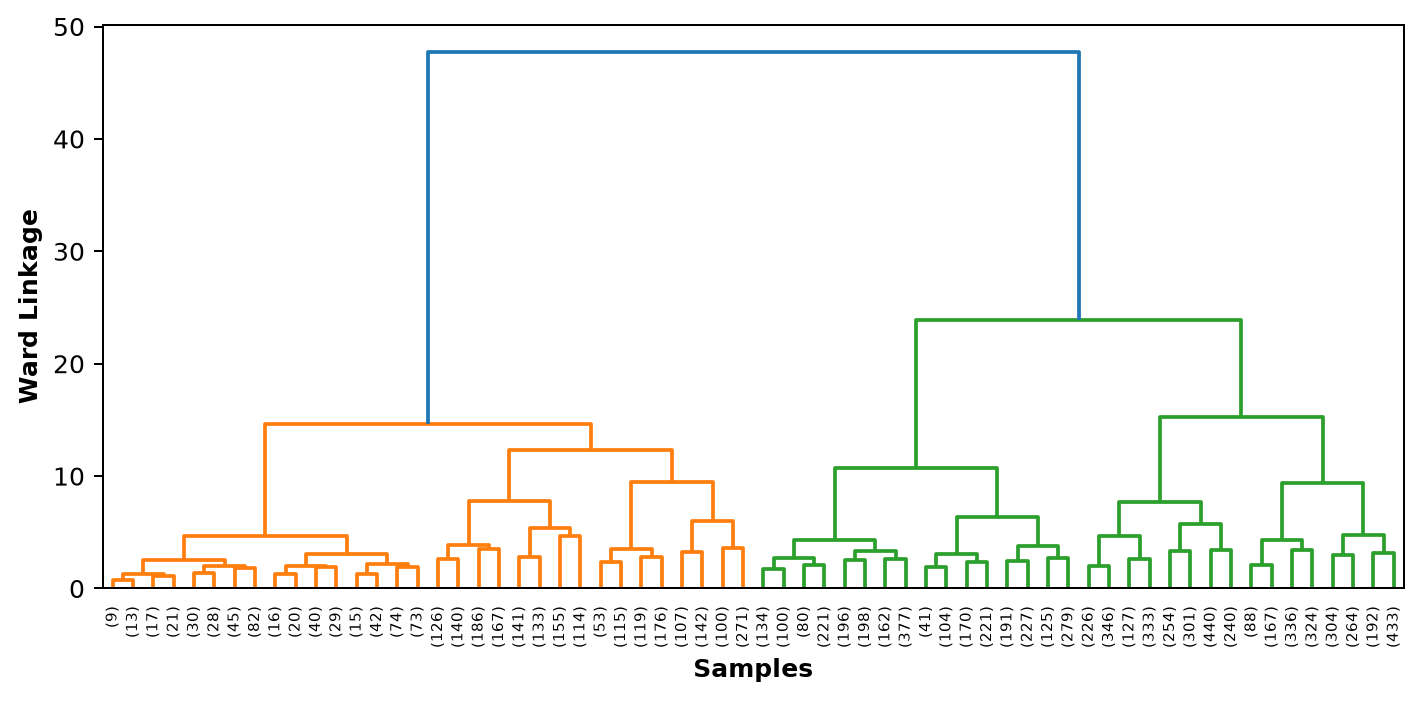

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Take a manageable random sample
rng = np.random.default_rng(seed)

sample_size = 10_000
idx = rng.choice(X_norm.shape[0], size=sample_size, replace=False)
X_sample = X_norm[idx]

# Hierarchical clustering
Z = linkage(
    X_sample,
    method="ward",
    metric="euclidean"
)

# Dendrogram
plt.figure(figsize=(8, 4))

dendrogram(
    Z,
    truncate_mode="level",
    p=5
)

plt.xlabel("Samples", fontweight="bold")
plt.ylabel("Ward Linkage", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/dissertation/figures/dendrogram.png", dpi=300)
plt.show()

In [55]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(seed)

aris = []

for i in tqdm(range(1000)):
    idx = rng.choice(X_norm.shape[0], size=10_000, replace=False)

    X_sample = X_norm[idx]
    kmeans_sample = clusters[idx]

    Z = linkage(
        X_sample,
        method="ward",
        metric="euclidean"
    )

    agg_labels = fcluster(
        Z,
        t=2,
        criterion="maxclust"
    )

    ari = adjusted_rand_score(kmeans_sample, agg_labels)
    aris.append(ari)

print("ARI values:", aris)
print("Mean:", np.mean(aris))
print("SD:", np.std(aris))

100%|██████████| 1000/1000 [1:04:30<00:00,  3.87s/it]


ARI values: [0.6228431006659585, 0.6006714262981082, 0.6161281204672494, 0.3792450106060133, 0.6417642451414364, 0.7368859833959918, 0.4904384185314483, 0.43363414482520124, 0.6763287040758035, 0.40986484934988465, 0.46233180814816466, 0.6085387424737039, 0.5375755034979394, 0.507891099722797, 0.6195934900727497, 0.8275936270649084, 0.5795016320753492, 0.5363942574241027, 0.4774002882705447, 0.38899807442187284, 0.6769747260423356, 0.4647629596252294, 0.7616357184339655, 0.6685192772855796, 0.43087677806323194, 0.7616867234912661, 0.49308737746422476, 0.5626453283131299, 0.4578743600975413, 0.4349318871977196, 0.5944342227074068, 0.7306141137078132, 0.6658382800042599, 0.6716968960490527, 0.4235376427781943, 0.5462049035330977, 0.6223899024126501, 0.7590906721083229, 0.6147133750985897, 0.24412624333419916, 0.5845075444320686, 0.7928513129749769, 0.2965009109706088, 0.7461665765171823, 0.519065807439799, 0.7103970546340025, 0.4681962515522886, 0.568011726610943, 0.3892441756116341, 0.5

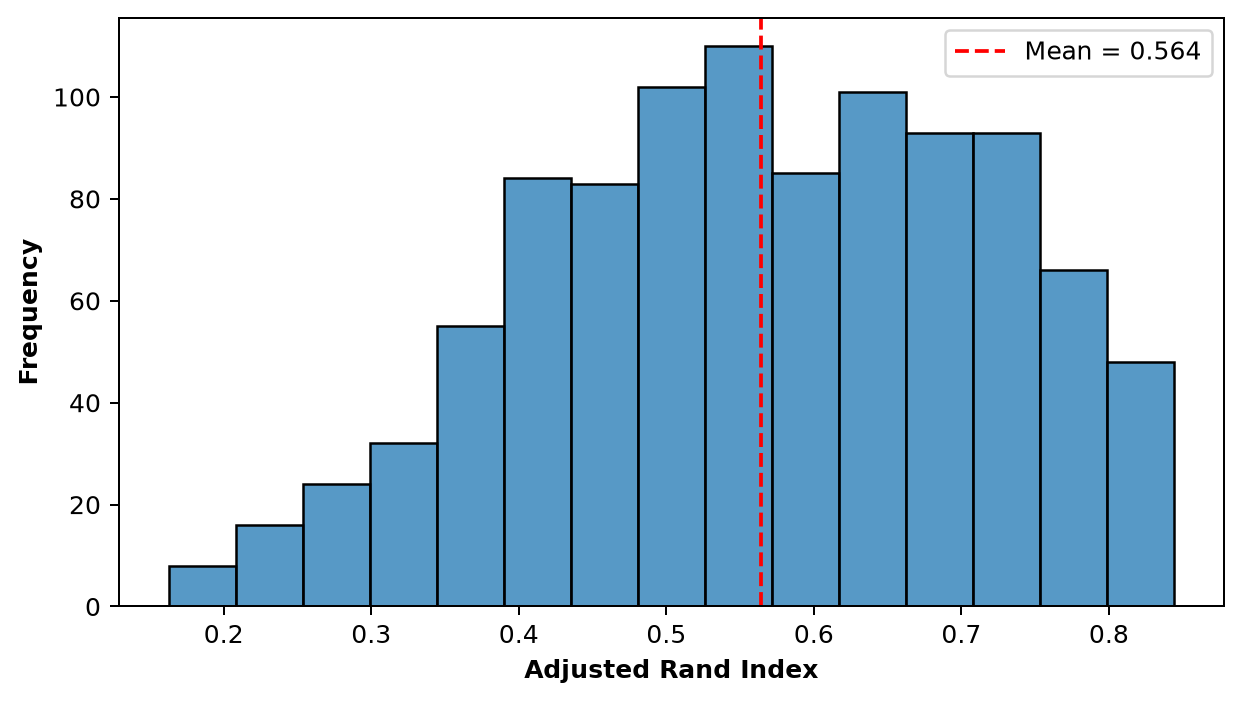

In [58]:
plt.figure(figsize=(7, 4))

sns.histplot(
    aris,
    edgecolor="black"
)

plt.axvline(
    np.mean(aris),
    linestyle="--",
    color="red",
    label=f"Mean = {np.mean(aris):.3f}"
)

plt.xlabel("Adjusted Rand Index", fontweight="bold")
plt.ylabel("Frequency", fontweight="bold")
plt.legend()

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/ari_clustering_distribution_histogram.png", dpi=300)
plt.show()

In [66]:
atomic_actions_df[atomic_actions_df["game_id"] == 3869685]

,game_id,action_id,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,...,spatial_embedding_63_a9,concedes,scores,pconcedes,pscores,team_id,type_name,offensive_value,defensive_value,vaep_value
380495,3869685,0,1,0,0,0,0,0,0,0,...,0.000000,0,0,0.000635,0.001254,771,pass,0.001082,0.131314,0.132395
380496,3869685,1,0,0,0,0,0,0,0,0,...,0.000000,0,0,0.000535,0.001036,771,receival,-0.000217,0.000099,-0.000118
380497,3869685,2,0,0,0,0,0,0,0,0,...,0.000000,0,0,0.000737,0.002559,771,dribble,0.001523,-0.000202,0.001321
380498,3869685,3,1,0,0,0,0,0,0,0,...,0.000000,0,0,0.000421,0.003624,771,pass,0.001065,0.000315,0.001381
380499,3869685,4,0,0,0,0,0,0,0,0,...,0.000000,0,0,0.000223,0.006129,771,out,0.002505,0.000199,0.002704
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
384447,3869685,3952,0,0,0,0,0,0,0,0,...,0.000000,1,1,0.766595,0.999693,779,goal,0.129013,-0.070682,0.058331
384448,3869685,3953,0,0,0,0,0,0,0,0,...,0.000000,1,1,0.791185,0.916301,771,shot_penalty,0.916301,-0.791185,0.125116
384449,3869685,3954,0,0,0,0,0,0,0,0,...,2.798356,1,1,0.766586,0.999050,771,goal,0.082749,0.024600,0.107349
384450,3869685,3955,0,0,0,0,0,0,0,0,...,2.798356,0,1,0.625227,0.897177,779,shot_penalty,0.897177,-0.625227,0.271949
